In [ ]:
import os
import sys
import zipfile

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from tqdm import tqdm
from neo4j import GraphDatabase
from scipy.sparse import csr_matrix, triu
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import LabelEncoder

In [ ]:
URI = "neo4j://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = "....."

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

try:
    driver.verify_connectivity()
    print("Koneksi ke Neo4j berhasil!")
finally:
    driver.close()

Koneksi ke Neo4j berhasil!


In [ ]:
import neo4j
print(neo4j.__version__)

from neo4j import GraphDatabase, RoutingControl
print("Impor berhasil")

5.26.0
Impor berhasil


In [ ]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", ".....")

In [6]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )

In [7]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )

    for record in records:
        print(record["friend.name"])

In [8]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### Pertanyaan Pendahuluan

1.Apa nama database yang digunakan pada tutorial ini?

Nama database yang digunakan adalah `neo4j`

2.Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!

Selain menggunakan Python Driver, database Neo4j juga bisa diakses menggunakan perintah Cypher. Contohnya, CREATE untuk membuat node atau relasi, MATCH untuk mencari data, SET untuk mengubah data, dan DELETE untuk menghapus data. Untuk mengakses database lain dalam satu instance, kita bisa menentukan nama database yang ingin digunakan pada saat membuat session atau menjalankan query

3.Apa jenis graf pertemanan yang telah dibuat di sini?

Graf pertemanan yang dibuat adalah graf berarah (directed graph), karena hubungan KNOWS memiliki arah dari satu orang ke orang lain. Pada contoh ini, Arthur memiliki hubungan KNOWS dengan Guinevere, Lancelot, dan Merlin. Graf tersebut terdiri dari node berlabel Person sebagai orang dan relasi KNOWS sebagai hubungan pertemanan. Hubungan ini ditunjukkan dari Arthur menuju ketiga orang tersebut


In [ ]:
zip_path = "ecommerce-dataset.zip"
extract_path = "data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak.")
print(os.listdir(extract_path))

Dataset berhasil diekstrak.
['category_tree.csv', 'events.csv', 'item_properties_part1.csv', 'item_properties_part2.csv', 'testing.csv', 'training.csv']


In [ ]:
df = pd.read_csv("data/events.csv", nrows=5)
df

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [11]:
uri = URI
user = AUTH[0]
password = AUTH[1]

In [ ]:
driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="system")

In [ ]:
csv_file_path = os.path.join("data", "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

print(f"File ditemukan: {csv_file_path}")

File ditemukan: data\events.csv


In [14]:
try:
    driver = GraphDatabase.driver(
        URI, auth=AUTH
    )
    driver.verify_connectivity()
    print("Koneksi ke Neo4j berhasil.")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

Koneksi ke Neo4j berhasil.


In [15]:
def create_constraints(session):
    constraints = [
        """
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
        """,
        """
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
        """
    ]

    for query in constraints:
        session.run(query)

In [ ]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [ ]:
batch_size = 10000

with driver.session(database="neo4j") as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size
    )

    total_rows = sum(
        1 for _ in open(csv_file_path, encoding="utf-8")
    ) - 1

    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")

    for chunk in tqdm(
        chunks,
        total=total_chunks,
        desc="Mengimpor Batch Data"
    ):
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")


Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [05:11<00:00,  1.13s/it]

Proses impor berhasil.


# Wrangling EDA 2.1

### Soal 1

Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak
boleh sama dalam 1 kelas.
Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024.

In [16]:
import pandas as pd

df = pd.read_csv("data/events.csv")

df["tanggal"] = pd.to_datetime(
    df["timestamp"], unit="ms"
)

print("Tanggal paling awal:", df["tanggal"].min())
print("Tanggal paling akhir:", df["tanggal"].max())

Tanggal paling awal: 2015-05-03 03:00:04.384000
Tanggal paling akhir: 2015-09-18 02:59:47.788000


In [17]:
df = pd.read_csv(
    "data/events.csv",
    usecols=["timestamp"]
)

df["tanggal"] = pd.to_datetime(
    df["timestamp"],
    unit="ms"
)


jumlah_harian = (
    df.groupby(df["tanggal"].dt.date)
      .size()
      .rename("jumlah_interaksi")
)

kumulatif = jumlah_harian.cumsum()

target_training = len(df) * 0.80

tanggal_batas = (
    (kumulatif - target_training)
    .abs()
    .idxmin()
)

print("Total interaksi:", len(df))
print("Target training 80%:", round(target_training))
print("Tanggal batas P1:", tanggal_batas)
print("Interaksi kumulatif sampai batas:", kumulatif.loc[tanggal_batas])
print(
    "Persentase training:",
    round(kumulatif.loc[tanggal_batas] / len(df) * 100, 2),
    "%"
)

Total interaksi: 2756101
Target training 80%: 2204881
Tanggal batas P1: 2015-08-17
Interaksi kumulatif sampai batas: 2199888
Persentase training: 79.82 %


In [ ]:
periode = {
    "P1 mulai": "2015-05-03",
    "P1 selesai": "2015-08-17",
    "P2 mulai": "2015-08-18",
    "P2 selesai": "2015-09-18"
}

for nama, tanggal in periode.items():
    waktu = pd.Timestamp(tanggal, tz="UTC")
    unix_detik = int(waktu.timestamp())

    print(f"{nama} ({tanggal})")
    print(f"    UNIX detik    : {unix_detik}")

P1 mulai (2015-05-03)
    UNIX detik    : 1430611200
P1 selesai (2015-08-17)
    UNIX detik    : 1439769600
P2 mulai (2015-08-18)
    UNIX detik    : 1439856000
P2 selesai (2015-09-18)
    UNIX detik    : 1442534400


Berdasarkan hasil pengolahan data, periode interaksi pada dataset RetailRocket berlangsung dari 3 Mei 2015 hingga 18 September 2015 dengan total 2.756.101 interaksi. Pembagian periode dilakukan dengan menggunakan sekitar 80% data sebagai training (P1) dan sisanya sebagai testing (P2). Hasil perhitungan menunjukkan bahwa periode P1 ditetapkan pada 3 Mei–17 Agustus 2015 dengan total 2.199.888 interaksi atau sekitar 79,82% dari keseluruhan data. Sementara itu, periode P2 ditetapkan pada 18 Agustus–18 September 2015 sebagai data pengujian. Kedua periode tersebut tidak saling tumpang tindih sehingga data testing dapat digunakan untuk mengevaluasi hasil rekomendasi berdasarkan data training.

### Soal 2

Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [ ]:
df = pd.read_csv("data/events.csv")

df["tanggal"] = pd.to_datetime(
    df["timestamp"], unit="ms"
).dt.date

training = df[
    (df["tanggal"] >= pd.to_datetime("2015-05-03").date()) &
    (df["tanggal"] <= pd.to_datetime("2015-08-17").date())
]

testing = df[
    (df["tanggal"] >= pd.to_datetime("2015-08-18").date()) &
    (df["tanggal"] <= pd.to_datetime("2015-09-18").date())
]

training.drop(columns=["tanggal"]).to_csv(
    "data/training.csv", index=False
)

testing.drop(columns=["tanggal"]).to_csv(
    "data/testing.csv", index=False
)

print("Jumlah data training:", len(training))
print("Jumlah data testing:", len(testing))
print("File training.csv dan testing.csv berhasil disimpan.")

Jumlah data training: 2199888
Jumlah data testing: 556213
File training.csv dan testing.csv berhasil disimpan.


Berdasarkan proses filter timestamp, data interaksi RetailRocket dibagi menjadi dua file CSV, yaitu training.csv dan testing.csv. Data training diambil dari periode 3 Mei hingga 17 Agustus 2015 dengan jumlah 2.199.888 interaksi. Sementara itu, data testing diambil dari periode 18 Agustus hingga 18 September 2015 dengan jumlah 556.213 interaksi. Proses penyaringan dilakukan berdasarkan tanggal yang diperoleh dari kolom timestamp setelah dikonversi dari milidetik menjadi tanggal.

### Soal 3

Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah
masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [ ]:
training = pd.read_csv("data/training.csv")

print("UKURAN DATA TRAINING")
print(f"Jumlah baris dan kolom : {training.shape}")

print("\nNAMA KOLOM")
print(training.columns.tolist())

print("\n5 DATA PERTAMA")
display(training.head())

UKURAN DATA TRAINING
Jumlah baris dan kolom : (2199888, 5)

NAMA KOLOM
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

5 DATA PERTAMA


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [ ]:
driver = GraphDatabase.driver(
    uri,
    auth=(user, password)
)

driver.verify_connectivity()

print("Koneksi ke Neo4j berhasil.")

Koneksi ke Neo4j berhasil.


periode training

In [ ]:
batas_awal = int(
    pd.Timestamp("2015-05-03", tz="UTC").timestamp() * 1000
)

batas_akhir = int(
    pd.Timestamp("2015-08-18", tz="UTC").timestamp() * 1000
)

Menghitung komposisi node

In [31]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (v:Visitor)-[r]->(i:Item)
        WHERE r.timestamp >= $awal
          AND r.timestamp < $akhir
        RETURN
            count(DISTINCT v) AS jumlah_visitor,
            count(DISTINCT i) AS jumlah_item
    """, awal=batas_awal, akhir=batas_akhir)

    data_node = result.single().data()

komposisi_node = pd.DataFrame([
    {
        "jenis_node": "Visitor",
        "jumlah": data_node["jumlah_visitor"]
    },
    {
        "jenis_node": "Item",
        "jumlah": data_node["jumlah_item"]
    }
])

komposisi_node.loc[len(komposisi_node)] = [
    "TOTAL",
    komposisi_node["jumlah"].sum()
]

display(komposisi_node)

,jenis_node,jumlah
0,Visitor,1121163
1,Item,212675
2,TOTAL,1333838


Menghitung komposisi relationship

In [32]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (v:Visitor)-[r]->(i:Item)
        WHERE r.timestamp >= $awal
          AND r.timestamp < $akhir
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jenis_relasi
    """, awal=batas_awal, akhir=batas_akhir)

    data_relasi = [record.data() for record in result]

komposisi_relasi = pd.DataFrame(data_relasi)

komposisi_relasi.loc[len(komposisi_relasi)] = [
    "TOTAL",
    komposisi_relasi["jumlah"].sum()
]

display(komposisi_relasi)

,jenis_relasi,jumlah
0,ADDED_TO_CART,54875
1,BOUGHT,17834
2,VIEWED,2127179
3,TOTAL,2199888


In [33]:
training = pd.read_csv("data/training.csv")

print("Jumlah baris training:", len(training))
print("\nJumlah event pada training.csv:")
print(training["event"].value_counts().sort_index())

print(
    "\nTotal relationship P1 di Neo4j:",
    komposisi_relasi["jumlah"].iloc[:-1].sum()
)

Jumlah baris training: 2199888

Jumlah event pada training.csv:
event
addtocart        54875
transaction      17834
view           2127179
Name: count, dtype: int64

Total relationship P1 di Neo4j: 2199888


Berdasarkan hasil pengolahan data, file training.csv memiliki 2.199.888 baris interaksi dan 5 kolom, yaitu timestamp, visitorid, event, itemid, dan transactionid. Hasil query pada Neo4j menunjukkan terdapat 1.121.163 node Visitor dan 212.675 node Item, dengan total 1.333.838 node. Node Visitor merepresentasikan pengunjung, sedangkan node Item merepresentasikan barang yang diinteraksikan.

Berdasarkan jenis relasinya, terdapat 2.127.179 VIEWED, 54.875 ADDED_TO_CART, dan 17.834 BOUGHT, dengan total 2.199.888 relationship. Relasi VIEWED merupakan yang paling banyak, sedangkan BOUGHT paling sedikit. Query Cypher menggunakan MATCH untuk mencocokkan node dan relasi, count(DISTINCT ...) untuk menghitung jumlah node unik, serta type(r) dan count(r) untuk mengetahui jenis dan jumlah relasi. Jumlah relationship di Neo4j sesuai dengan jumlah baris pada training.csv, dan jumlah setiap jenis relasi juga sesuai dengan jumlah masing-masing event pada data training.

### Soal 4

Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

Membentuk matriks VSM User–Item

In [ ]:
user_enc = LabelEncoder()
item_enc = LabelEncoder()

u = user_enc.fit_transform(training["visitorid"])
i = item_enc.fit_transform(training["itemid"])

vsm_user = csr_matrix(
    (
        np.ones(len(training), dtype=np.int32),
        (u, i)
    ),
    shape=(len(user_enc.classes_), len(item_enc.classes_))
)

vsm_user.sum_duplicates()

print("Dimensi VSM User-Item:", vsm_user.shape)
print("Jumlah User:", vsm_user.shape[0])
print("Jumlah Item:", vsm_user.shape[1])
print("Jumlah pasangan User-Item unik:", vsm_user.nnz)
print("Jumlah seluruh interaksi:", vsm_user.sum())

kepadatan = vsm_user.nnz / (
    vsm_user.shape[0] * vsm_user.shape[1]
) * 100

print("Kepadatan matriks:", round(kepadatan, 6), "%")

Dimensi VSM User-Item: (1121163, 212675)
Jumlah User: 1121163
Jumlah Item: 212675
Jumlah pasangan User-Item unik: 1709310
Jumlah seluruh interaksi: 2199888
Kepadatan matriks: 0.000717 %


proyeksi jaringan 30 User

In [ ]:
interaksi_user = training["visitorid"].value_counts()
user_30_id = interaksi_user.head(30).index
indeks_30 = user_enc.transform(user_30_id)
vsm_30 = vsm_user[indeks_30].copy()

vsm_30.data[:] = 1

print("Dimensi VSM sampel:", vsm_30.shape)

proyeksi_30 = vsm_30 @ vsm_30.T

proyeksi_30.setdiag(0)
proyeksi_30.eliminate_zeros()

proyeksi_30 = triu(proyeksi_30, k=1).tocsr()

G_30 = nx.from_scipy_sparse_array(
    proyeksi_30,
    edge_attribute="bobot"
)

print("Jumlah simpul:", G_30.number_of_nodes())
print("Jumlah sisi:", G_30.number_of_edges())
print(
    "Jumlah komponen terhubung:",
    nx.number_connected_components(G_30)
)

Dimensi VSM sampel: (30, 212675)
Jumlah simpul: 30
Jumlah sisi: 434
Jumlah komponen terhubung: 1


Menghitung karakteristik jaringan

In [36]:
derajat_30 = dict(G_30.degree())

print("Rata-rata derajat:",
      round(np.mean(list(derajat_30.values())), 2))

print("Derajat tertinggi:",
      max(derajat_30.values(), default=0))

Rata-rata derajat: 28.93
Derajat tertinggi: 29


Plot jaringan menggunakan NetworkX

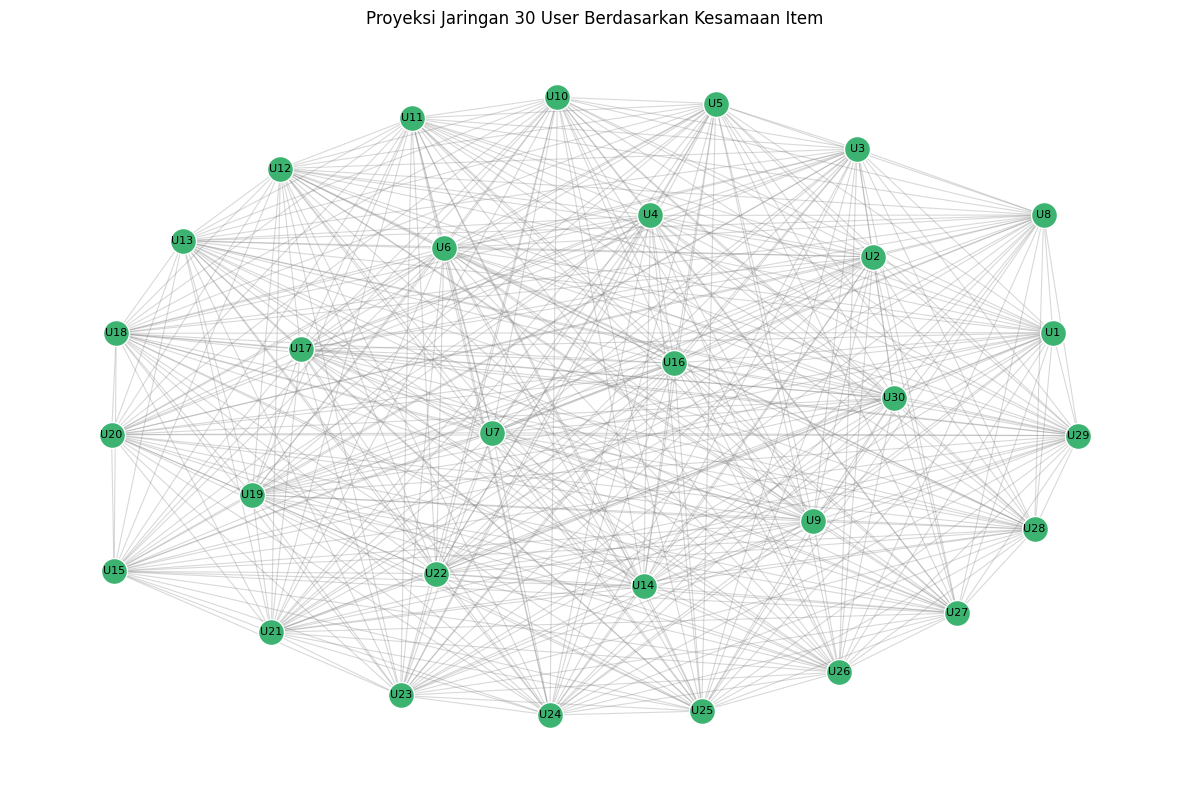

In [37]:
plt.figure(figsize=(12, 8))

posisi = nx.kamada_kawai_layout(G_30)

nx.draw_networkx_edges(
    G_30, posisi,
    edge_color="gray",
    alpha=0.3,
    width=0.8
)

nx.draw_networkx_nodes(
    G_30, posisi,
    node_color="mediumseagreen",
    node_size=350,
    edgecolors="white",
    linewidths=1
)

nx.draw_networkx_labels(
    G_30, posisi,
    labels={
        simpul: f"U{simpul + 1}"
        for simpul in G_30.nodes()
    },
    font_size=8
)

plt.title("Proyeksi Jaringan 30 User Berdasarkan Kesamaan Item")
plt.axis("off")
plt.tight_layout()
plt.show()

Berdasarkan hasil Vector Space Modelling (VSM), matriks User-Item memiliki dimensi \(1.121.163 \times 212.675\), yang terdiri dari 1.121.163 user dan 212.675 item. Terdapat 1.709.310 pasangan User-Item unik dari total 2.199.888 interaksi, dengan kepadatan matriks hanya 0,000717%. Hal ini menunjukkan bahwa matriks sangat jarang (sparse) karena sebagian besar user hanya berinteraksi dengan sebagian kecil item.

Untuk visualisasi jaringan, dipilih 30 user dengan jumlah interaksi terbanyak. Matriks sampel memiliki dimensi \(30 \times 212.675\), kemudian diproyeksikan menjadi jaringan berdasarkan kesamaan item yang diinteraksikan. Hasilnya terdapat 30 simpul dan 434 sisi, dengan rata-rata derajat 28,93 dan derajat tertinggi 29. Jaringan memiliki satu komponen terhubung, yang berarti seluruh user dalam sampel saling terhubung melalui kesamaan item. Pada plot NetworkX, simpul mewakili user, sedangkan sisi menunjukkan adanya kesamaan item antar-user.

### Soal 5

Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

Membuat VSM Item–User

In [ ]:
vsm_item = vsm_user.T.tocsr()

print("Dimensi VSM Item-User:", vsm_item.shape)
print("Jumlah Item:", vsm_item.shape[0])
print("Jumlah User:", vsm_item.shape[1])
print("Jumlah pasangan Item-User unik:", vsm_item.nnz)
print("Jumlah seluruh interaksi:", vsm_item.sum())

kepadatan_item = (
    vsm_item.nnz /
    (vsm_item.shape[0] * vsm_item.shape[1])
) * 100

print("Kepadatan matriks:", round(kepadatan_item, 6), "%")

Dimensi VSM Item-User: (212675, 1121163)
Jumlah Item: 212675
Jumlah User: 1121163
Jumlah pasangan Item-User unik: 1709310
Jumlah seluruh interaksi: 2199888
Kepadatan matriks: 0.000717 %


Membentuk proyeksi jaringan 30 Item

In [ ]:
interaksi_item = training["itemid"].value_counts()
item_terpilih = interaksi_item.head(30).index

indeks_item = item_enc.transform(item_terpilih)
vsm_sampel_item = vsm_item[indeks_item].copy()

vsm_sampel_item.data[:] = 1

print("Dimensi VSM sampel Item:", vsm_sampel_item.shape)

proyeksi_item = vsm_sampel_item @ vsm_sampel_item.T

proyeksi_item.setdiag(0)
proyeksi_item.eliminate_zeros()


proyeksi_item = triu(proyeksi_item, k=1).tocsr()

graf_item = nx.from_scipy_sparse_array(
    proyeksi_item,
    edge_attribute="bobot"
)

print("Jumlah simpul:", graf_item.number_of_nodes())
print("Jumlah sisi:", graf_item.number_of_edges())
print(
    "Jumlah komponen terhubung:",
    nx.number_connected_components(graf_item)
)

Dimensi VSM sampel Item: (30, 1121163)
Jumlah simpul: 30
Jumlah sisi: 297
Jumlah komponen terhubung: 2


Menghitung karakteristik jaringan

In [ ]:
derajat_item = dict(graf_item.degree())

print("Jumlah simpul:", graf_item.number_of_nodes())
print("Jumlah sisi:", graf_item.number_of_edges())

print(
    "Rata-rata derajat:",
    round(np.mean(list(derajat_item.values())), 2)
)

print(
    "Derajat tertinggi:",
    max(derajat_item.values(), default=0)
)

Jumlah simpul: 30
Jumlah sisi: 297
Rata-rata derajat: 19.8
Derajat tertinggi: 26


Visualisasi NetworkX

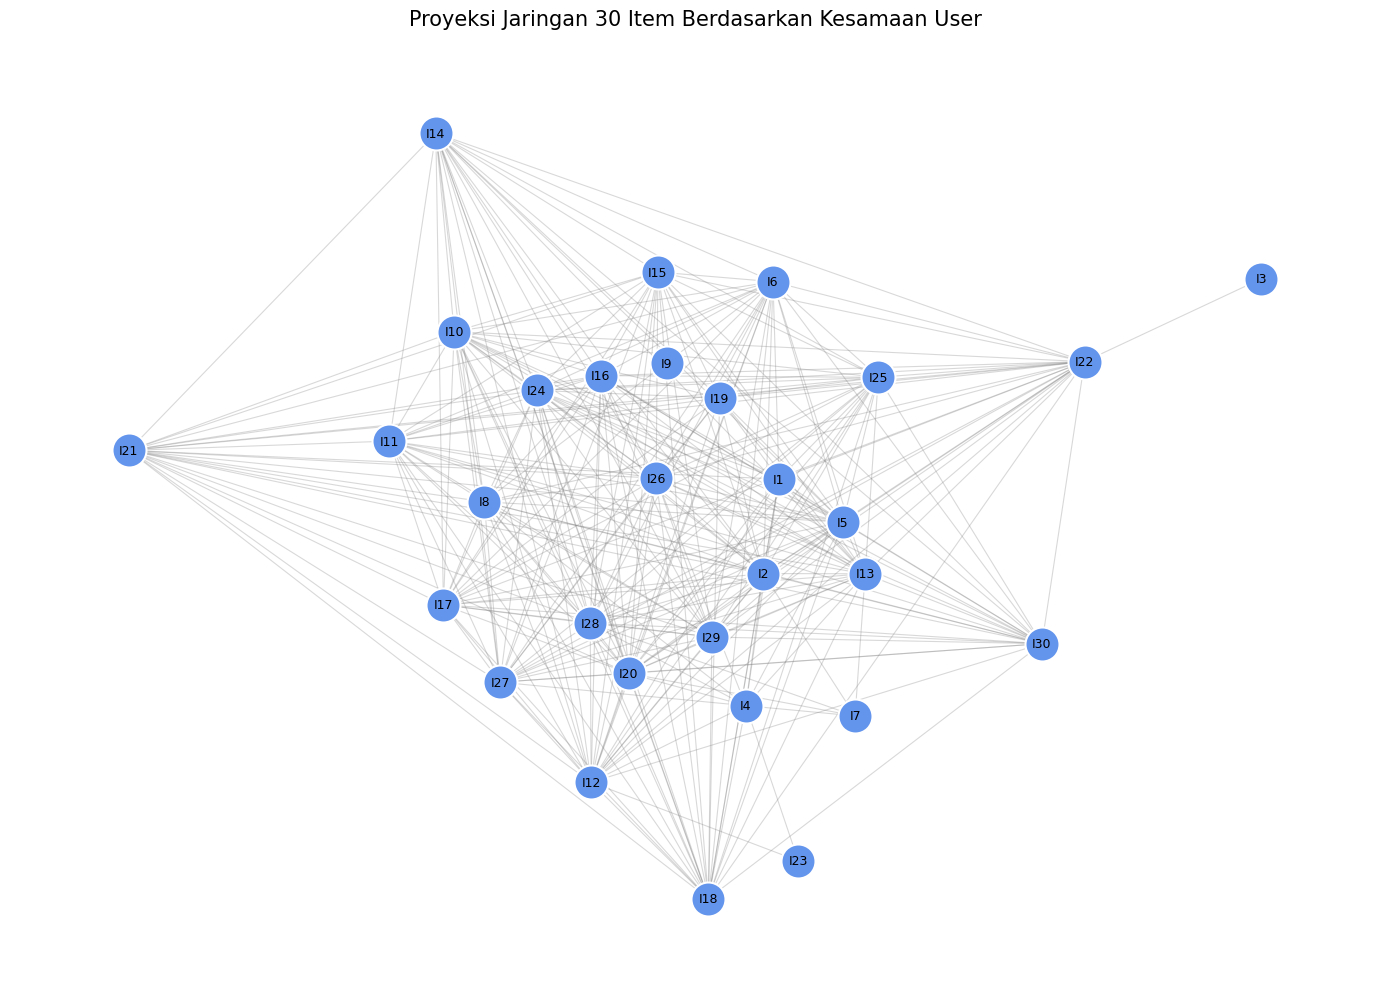

In [ ]:
plt.figure(figsize=(14, 10))

posisi = nx.kamada_kawai_layout(
    graf_item,
    weight="bobot"
)

nx.draw_networkx_edges(
    graf_item,
    posisi,
    edge_color="gray",
    alpha=0.3,
    width=0.8
)

nx.draw_networkx_nodes(
    graf_item,
    posisi,
    node_color="cornflowerblue",
    node_size=600,
    edgecolors="white",
    linewidths=1.5
)

nx.draw_networkx_labels(
    graf_item,
    posisi,
    labels={
        simpul: f"I{simpul + 1}"
        for simpul in graf_item.nodes()
    },
    font_size=9,
    font_weight="medium"
)

plt.title(
    "Proyeksi Jaringan 30 Item Berdasarkan Kesamaan User",
    fontsize=15,
    pad=20
)

plt.axis("off")
plt.tight_layout()
plt.show()

Berdasarkan hasil Vector Space Modelling (VSM), matriks Item-User memiliki dimensi \(212.675 \times 1.121.163\), yang terdiri dari 212.675 item dan 1.121.163 user. Terdapat 1.709.310 pasangan Item-User unik dari total 2.199.888 interaksi, dengan kepadatan matriks sebesar 0,000717%. Hal ini menunjukkan bahwa matriks sangat jarang (sparse) karena sebagian besar item hanya berinteraksi dengan sebagian kecil user.

Untuk visualisasi jaringan, dipilih 30 item dengan jumlah interaksi terbanyak. Matriks sampel memiliki dimensi \(30 \times 1.121.163\), kemudian diproyeksikan menjadi jaringan berdasarkan kesamaan user yang berinteraksi dengan item tersebut. Hasilnya terdapat 30 simpul dan 297 sisi, dengan rata-rata derajat 19,8 dan derajat tertinggi 26. Jaringan memiliki 2 komponen terhubung, yang berarti terdapat dua kelompok item yang saling terhubung berdasarkan kesamaan user. Pada plot NetworkX, simpul mewakili item, sedangkan sisi menunjukkan kesamaan user antar-item.

### Soal 6

Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Berdasarkan hasil eksplorasi nomor 4 dan 5, proyeksi Item lebih efisien dari segi jumlah sisi, sedangkan proyeksi User lebih efektif dalam menunjukkan keterhubungan jaringan. Proyeksi User memiliki 30 simpul dan 434 sisi yang membentuk satu komponen terhubung. Artinya, seluruh User dalam sampel saling terhubung berdasarkan kesamaan Item yang diakses. Sementara itu, proyeksi Item memiliki 30 simpul dan 297 sisi yang terbagi menjadi dua komponen terhubung. Jumlah sisi yang lebih sedikit membuat proyeksi Item lebih sederhana untuk dianalisis, sedangkan dua komponen menunjukkan bahwa tidak semua Item dalam sampel saling terhubung berdasarkan kesamaan User. Jadi, jika tujuan analisis adalah melihat hubungan antar-User, proyeksi User lebih efektif. Jika tujuan analisis adalah melihat hubungan antar-Item dengan jumlah sisi yang lebih sedikit, proyeksi Item lebih efisien. Penilaian efisiensi ini berdasarkan jumlah sisi, bukan waktu komputasi karena waktu pemrosesan kedua proyeksi belum diukur.

### Soal 7

Berdasarkan analisis nomor 6, lakukan perhitungan similarity pada hasil graf yang diproyeksikan dengan menggunakan Python.

(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!


In [ ]:
tetangga = {
    node: set(graf_item.neighbors(node))
    for node in graf_item.nodes()
}

node_acuan = 0
item_acuan = int(item_terpilih[node_acuan])

hasil_similarity = []

for node_lain in graf_item.nodes():
    if node_lain == node_acuan:
        continue

    irisan = tetangga[node_acuan] & tetangga[node_lain]
    gabungan = tetangga[node_acuan] | tetangga[node_lain]

    similarity = len(irisan) / len(gabungan) if gabungan else 0

    hasil_similarity.append({
        "itemId1": item_acuan,
        "itemId2": int(item_terpilih[node_lain]),
        "similarity": similarity
    })

hasil_similarity.sort(
    key=lambda x: x["similarity"],
    reverse=True
)

top_5_similarity = hasil_similarity[:5]

print("Item acuan:", item_acuan)
print("\n5 Item dengan similarity tertinggi:")

for nomor, data in enumerate(top_5_similarity, start=1):
    print(
        nomor,
        "| Item acuan:", data["itemId1"],
        "| Item mirip:", data["itemId2"],
        "| Similarity:", round(data["similarity"], 4)
    )


Item acuan: 5411

5 Item dengan similarity tertinggi:
1 | Item acuan: 5411 | Item mirip: 91755 | Similarity: 0.625
2 | Item acuan: 5411 | Item mirip: 133814 | Similarity: 0.625
3 | Item acuan: 5411 | Item mirip: 441668 | Similarity: 0.6087
4 | Item acuan: 5411 | Item mirip: 48030 | Similarity: 0.5833
5 | Item acuan: 5411 | Item mirip: 384302 | Similarity: 0.5833


Simpan similarity ke Neo4j

In [ ]:
query_simpan = """
UNWIND $rows AS row
MATCH (a:Item)
WHERE toString(a.itemId) = toString(row.itemId1)
MATCH (b:Item)
WHERE toString(b.itemId) = toString(row.itemId2)
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = row.similarity
RETURN count(r) AS jumlah_relasi
"""

with driver.session() as session:
    hasil = session.run(
        query_simpan,
        rows=hasil_similarity
    ).single()

print("Relasi similarity yang diproses:", hasil["jumlah_relasi"])

Relasi similarity yang diproses: 870


Tampilkan 5 similarity tertinggi dengan Cypher

In [55]:
item_acuan = int(item_terpilih[0])
print("Item acuan:", item_acuan)

Item acuan: 5411


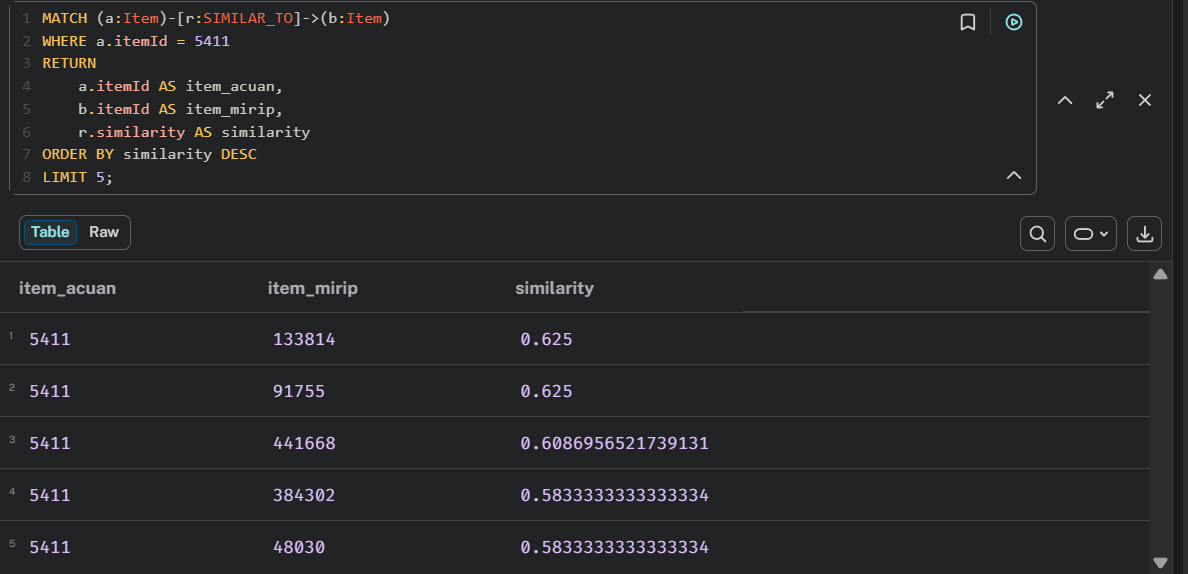

Perhitungan similarity dilakukan menggunakan metode Jaccard Similarity pada graf Item hasil proyeksi dengan Python. Item 5411 dipilih sebagai Item acuan. Perhitungan dilakukan dengan membandingkan kesamaan tetangga antar-Item, kemudian nilai similarity diurutkan dari tertinggi. Query Cypher digunakan untuk menampilkan lima Item dengan nilai similarity tertinggi yang telah tersimpan pada relasi SIMILAR_TO. Hasilnya menunjukkan bahwa Item 133814 dan 91755 memiliki nilai similarity sebesar 0.625, Item 441668 sebesar 0.6087, serta Item 384302 dan 48030 masing-masing sebesar 0.5833. Hasil tersebut menunjukkan lima Item yang memiliki kemiripan tetangga tertinggi terhadap Item acuan 5411 berdasarkan metode Jaccard.



(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!

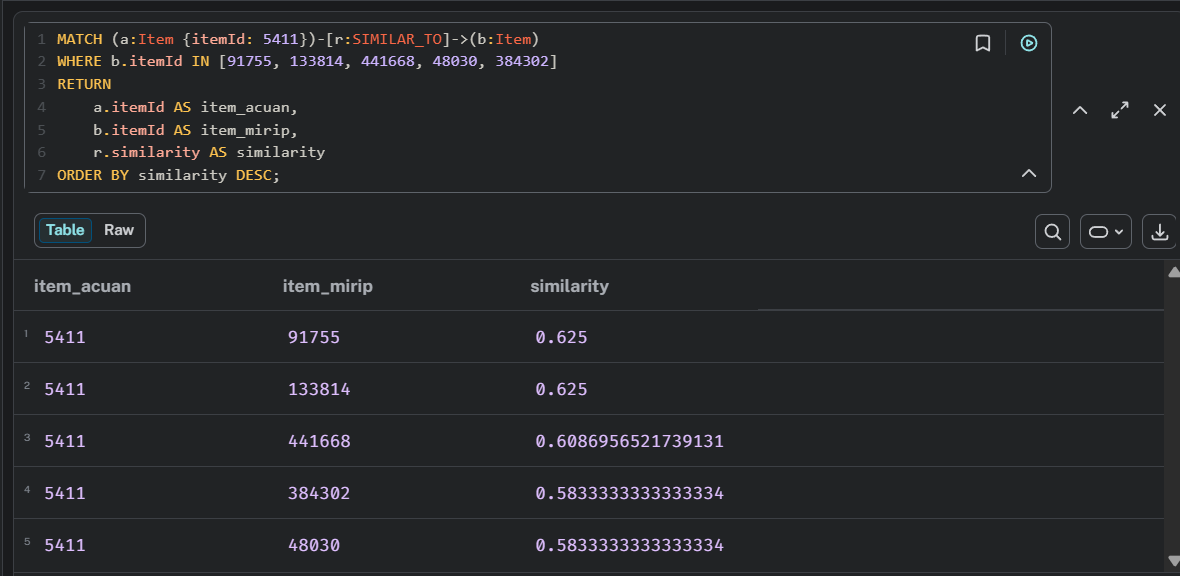

Nilai similarity hasil perhitungan Python disimpan pada graf Neo4j sebagai properti similarity dalam relasi SIMILAR_TO. Selanjutnya, query Cypher dijalankan untuk menampilkan kembali nilai similarity dari lima Item yang memiliki kemiripan tertinggi terhadap Item acuan 5411. Hasil query menunjukkan bahwa Item 91755 dan 133814 memiliki nilai similarity sebesar 0.625, Item 441668 sebesar 0.6087, serta Item 384302 dan 48030 masing-masing sebesar 0.5833.

Nomor 8

Sebelum perhitungan similarity

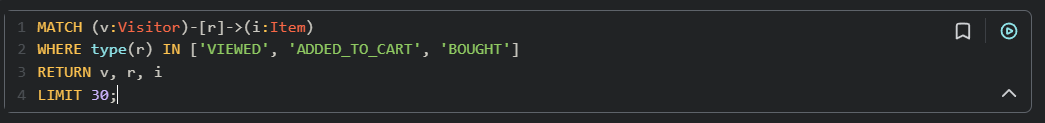

![visualisation FIKS 8.1.png](<attachment:visualisation FIKS 8.1.png>)
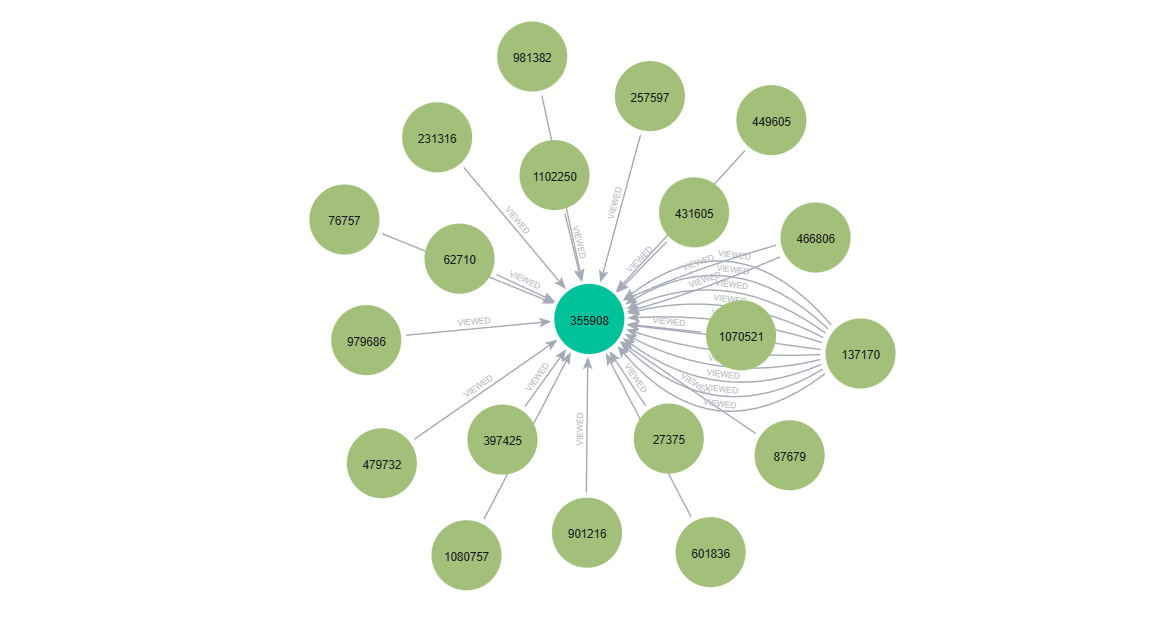

Query tersebut menampilkan 30 hubungan interaksi antara Visitor dan Item dengan jenis relasi VIEWED, ADDED_TO_CART, dan BOUGHT.

Pada gambar, lingkaran hijau muda menunjukkan Visitor, sedangkan lingkaran hijau toska di tengah dengan ID 355900 menunjukkan Item. Garis berpanah menunjukkan jenis interaksi pengunjung terhadap barang. Terlihat bahwa satu Item dapat terhubung dengan banyak Visitor dan beberapa Visitor memiliki lebih dari satu jenis interaksi terhadap Item yang sama. Hal ini menunjukkan bahwa aktivitas pengunjung terhadap barang tidak hanya berupa melihat, tetapi juga dapat berupa menambahkan barang ke keranjang atau membeli barang.

Sesudah perhitungan similarity

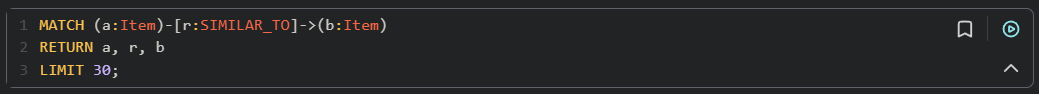

![visualisation FIKS 8.2.png](<attachment:visualisation FIKS 8.2.png>)
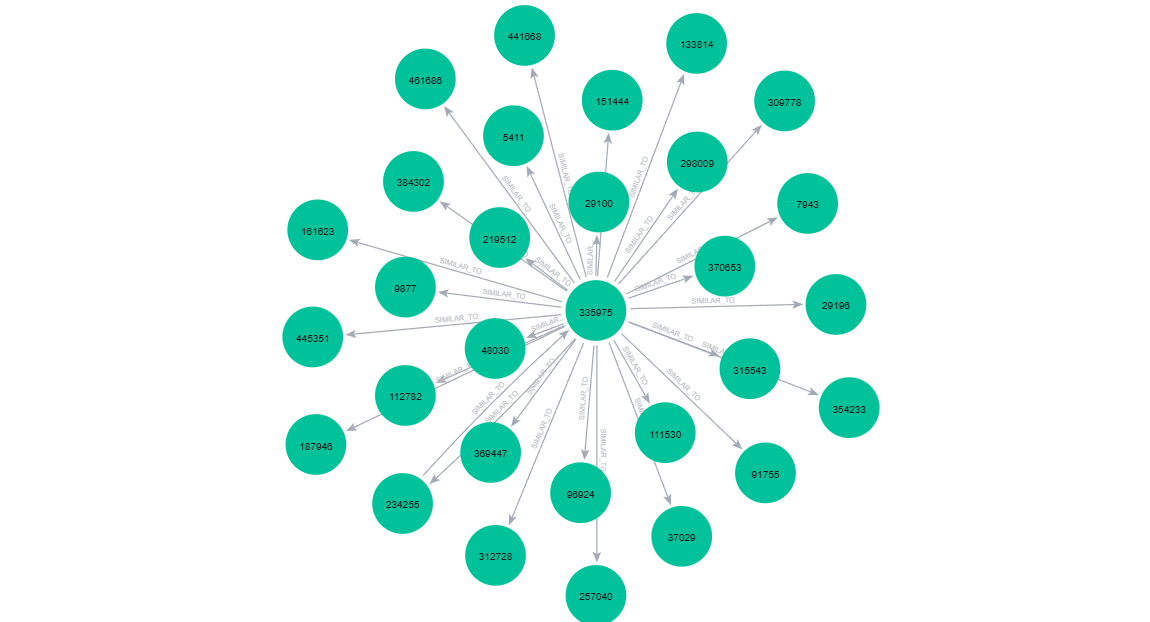

Query tersebut menampilkan maksimal 30 relasi SIMILAR_TO yang menghubungkan satu Item dengan Item lainnya.

Pada gambar, setiap lingkaran hijau toska menunjukkan Item berdasarkan ID-nya, sedangkan garis berpanah menunjukkan hubungan kemiripan antar-Item. Terlihat bahwa Item dengan ID 335975 terhubung dengan beberapa Item lain. Hubungan ini menunjukkan bahwa Item-Item tersebut memiliki nilai similarity yang tersimpan pada graf Neo4j berdasarkan hasil perhitungan Jaccard similarity.

## 2.2 Analytics

### Soal 1
Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

Persiapan Data

In [92]:
training = pd.read_csv("data/training.csv")
testing = pd.read_csv("data/testing.csv")

print("Jumlah baris training:", len(training))
print("Jumlah User unik:", training["visitorid"].nunique())
print("Jumlah Item unik:", training["itemid"].nunique())

Jumlah baris training: 2199888
Jumlah User unik: 1121163
Jumlah Item unik: 212675


Membentuk matriks User–Item

In [ ]:

user_enc = pd.Index(training["visitorid"].unique())
item_enc = pd.Index(training["itemid"].unique())

user_index = user_enc.get_indexer(training["visitorid"])
item_index = item_enc.get_indexer(training["itemid"])

vsm_user = csr_matrix(
    (
        np.ones(len(training), dtype=np.int32),
        (user_index, item_index)
    ),
    shape=(len(user_enc), len(item_enc))
)

vsm_user.sum_duplicates()
vsm_user.data[:] = 1

print("Dimensi matriks User-Item:", vsm_user.shape)
print("Jumlah pasangan User-Item unik:", vsm_user.nnz)

Dimensi matriks User-Item: (1121163, 212675)
Jumlah pasangan User-Item unik: 1709310


Menyiapkan kandidat User

In [ ]:
jumlah_item = training.groupby("visitorid")["itemid"].nunique()

user_training = set(jumlah_item[jumlah_item >= 5].index)
user_testing = set(testing["visitorid"].unique())

kandidat_user = np.array(
    sorted(user_training & user_testing)
)

if len(kandidat_user) == 0:
    raise ValueError("Tidak ada kandidat User yang memenuhi syarat.")

random_seed = 42
rng = np.random.default_rng(random_seed)
urutan_kandidat = rng.permutation(kandidat_user)

item_per_user = (
    training.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

print("Random seed:", random_seed)
print("Jumlah kandidat awal:", len(kandidat_user))

Random seed: 42
Jumlah kandidat awal: 3042


### (a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

 Memilih User target

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
user_target = None

for calon_user in urutan_kandidat:
    idx_target = user_enc.get_loc(calon_user)

    sim = cosine_similarity(
        vsm_user[idx_target],
        vsm_user
    ).ravel()

    sim[idx_target] = -1
    idx_knn = np.argsort(sim)[::-1][:5]

    if len(idx_knn) < 5:
        continue

    item_kandidat = set()

    for idx_user in idx_knn:
        user_tetangga = user_enc[idx_user]
        item_kandidat.update(
            item_per_user.get(user_tetangga, set())
        )

    item_kandidat -= item_per_user[calon_user]

    if len(item_kandidat) >= 5:
        user_target = int(calon_user)
        indeks_knn = idx_knn
        skor_similarity = sim
        break

if user_target is None:
    raise ValueError(
        "Tidak ditemukan User dengan minimal 5 kandidat item baru."
    )

print("User target:", user_target)
print("Jumlah Item unik di training:", len(item_per_user[user_target]))

User target: 646301
Jumlah Item unik di training: 17


Menampilkan lima tetangga terdekat

In [ ]:
hasil_knn = pd.DataFrame({
    "visitorid": user_enc[indeks_knn],
    "cosine_similarity": skor_similarity[indeks_knn]
})

print("Lima tetangga terdekat (k=5):")
print(hasil_knn.to_string(index=False))


Lima tetangga terdekat (k=5):
 visitorid  cosine_similarity
     65270           0.690268
     65477           0.688033
   1134806           0.650791
     61601           0.648204
    182312           0.646762


Metode K-Nearest Neighbors (KNN) digunakan untuk merekomendasikan item berdasarkan kemiripan riwayat interaksi antar-User. Pemilihan User target dilakukan secara acak menggunakan random seed 42 agar prosesnya dapat diulang. Berdasarkan hasil program, diperoleh User target dengan ID 646301. Selanjutnya, kemiripan antara User target dan User lainnya dihitung menggunakan cosine similarity. Lima User dengan nilai kemiripan tertinggi dipilih sebagai tetangga terdekat, yaitu User 65270, 65477, 1134806, 61601, dan 182312.

Riwayat interaksi kelima tetangga tersebut digunakan untuk menghitung skor rekomendasi item yang belum pernah dilihat oleh User target. Dalam proses pemilihan User, digunakan kriteria tambahan berupa ketersediaan minimal lima item baru yang dapat direkomendasikan. Hasil perhitungan ini digunakan untuk menentukan item yang direkomendasikan pada nomor 1(b).


### (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

Menghitung skor dan mengurutkan rekomendasi

In [ ]:
matriks_tetangga = vsm_user[indeks_knn]
bobot_tetangga = skor_similarity[indeks_knn]

skor_item = np.asarray(
    matriks_tetangga.T @ bobot_tetangga
).ravel()

item_dilihat = item_per_user[user_target]

for item in item_dilihat:
    skor_item[item_enc.get_loc(item)] = 0

peringkat_item = sorted(
    [
        (item_enc[i], float(skor_item[i]))
        for i in range(len(skor_item))
        if skor_item[i] > 0
    ],
    key=lambda x: (-x[1], x[0])
)

if len(peringkat_item) < 5:
    raise ValueError("Jumlah kandidat rekomendasi kurang dari 5.")

rekomendasi_top5 = [
    item for item, skor in peringkat_item[:5]
]

hasil_rekomendasi = pd.DataFrame(
    peringkat_item[:5],
    columns=["itemid", "skor_rekomendasi"]
)

print("Tiga rekomendasi item:")
print(hasil_rekomendasi.head(3).to_string(index=False))

Tiga rekomendasi item:
 itemid  skor_rekomendasi
 325310          2.633790
 268972          2.026505
 239006          1.987028


Berdasarkan hasil perhitungan KNN dengan (k=5), diperoleh tiga item dengan skor rekomendasi tertinggi untuk User target 646301. Hasil rekomendasi diurutkan berdasarkan skor dari yang tertinggi hingga terendah sebagai berikut:

1. Item 325310 dengan skor 2,633790.
2. Item 268972 dengan skor 2,026505.
3. Item 239006 dengan skor 1,987028.

Item 325310 menempati peringkat pertama karena memiliki skor rekomendasi tertinggi, yaitu 2,633790. Selanjutnya, item 268972 berada di peringkat kedua dan item 239006 di peringkat ketiga. Ketiga item tersebut belum pernah dilihat oleh User target dan memperoleh skor berdasarkan riwayat interaksi lima tetangga terdekat. Hasil ini menunjukkan bahwa item dengan skor lebih tinggi ditempatkan pada urutan rekomendasi yang lebih tinggi.

### Soal 2

Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

(a) Hit@5

(b) NDCG@5

In [ ]:
item_relevan = set(
    testing.loc[
        testing["visitorid"] == user_target,
        "itemid"
    ].unique()
)

relevansi = np.array([
    int(item in item_relevan)
    for item in rekomendasi_top5
])

hit_at_5 = int(np.sum(relevansi) > 0)

diskon = 1 / np.log2(np.arange(2, 7))
dcg_at_5 = float(np.sum(relevansi * diskon))

jumlah_ideal = min(len(item_relevan), 5)

if jumlah_ideal > 0:
    idcg_at_5 = float(
        np.sum(
            1 / np.log2(np.arange(2, jumlah_ideal + 2))
        )
    )
else:
    idcg_at_5 = 0.0

ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

print("User target:", user_target)
print("Jumlah item relevan di testing:", len(item_relevan))
print("Lima rekomendasi:", rekomendasi_top5)
print("Vektor relevansi:", relevansi.tolist())
print("Hit@5 =", hit_at_5)
print("DCG@5 =", round(dcg_at_5, 6))
print("IDCG@5 =", round(idcg_at_5, 6))
print("NDCG@5 =", round(ndcg_at_5, 4))


User target: 646301
Jumlah item relevan di testing: 9
Lima rekomendasi: [np.int64(325310), np.int64(268972), np.int64(239006), np.int64(269085), np.int64(44826)]
Vektor relevansi: [0, 0, 0, 1, 0]
Hit@5 = 1
DCG@5 = 0.430677
IDCG@5 = 2.948459
NDCG@5 = 0.1461


Evaluasi dilakukan dengan membandingkan lima item rekomendasi teratas dengan item yang terdapat pada data pengujian untuk User target 646301. Dari sembilan item unik yang terdapat pada data pengujian, diperoleh vektor relevansi [0, 0, 0, 1, 0]. Angka 1 menunjukkan bahwa item rekomendasi pada peringkat keempat, yaitu item 269085, terdapat dalam data pengujian. Sementara itu, empat item lainnya tidak ditemukan dalam data pengujian. Nilai Hit@5 yang diperoleh adalah 1 karena terdapat setidaknya satu item relevan dalam lima rekomendasi teratas.

Perhitungan NDCG@5 menghasilkan nilai DCG@5 sebesar 0,430677 dan IDCG@5 sebesar 2,948459, sehingga diperoleh NDCG@5 sebesar 0,1461. Nilai DCG menunjukkan kontribusi item relevan berdasarkan posisinya dalam daftar rekomendasi, sedangkan IDCG merupakan nilai ideal jika item relevan menempati posisi teratas. Nilai NDCG@5 sebesar 0,1461 menunjukkan bahwa urutan rekomendasi masih jauh dari kondisi ideal. Hal ini terjadi karena item relevan berada pada peringkat keempat, sehingga kontribusinya lebih kecil dibandingkan jika item tersebut berada pada peringkat pertama. Hasil evaluasi menunjukkan bahwa rekomendasi memuat satu item relevan, tetapi posisi item tersebut masih belum optimal.